# Broadband Access — Two Ways to Publish a Number That Is Not There

**Artifact class:** `tutorial`  ·  **Data mode:** `empirical`  ·  **Vintage:** ACS 2023 5-Year (pinned)

D01, D03, D06 and D07 worked at state level, where ACS margins are narrow enough that the
interesting question is which comparisons survive them. This notebook moves to **county** level,
where they usually do not, and where two separate failure modes sit directly in the path of the
obvious analysis.

**The first is a definition.** ACS table B28002 has a row called *Broadband of any type*. It
includes a cellular data plan. A household whose only connection is a phone is counted in it. So
is a household with fibre. The row most people reach for when they say "broadband access" and the
row that describes fixed home connectivity are different rows, and they rank the country
differently.

**The second is a reliability screen that certifies the wrong thing.** The conventional
coefficient-of-variation test asks whether an estimate's *level* is precise enough to publish.
A county broadband league table does not consume the level; it consumes the *rank*. Nearly every
county in this data passes the CV screen, and nearly none of their ranks are determined.

Both are demonstrated against the live table rather than asserted.

Real data only. No synthetic fallback. *Proprietary. SPDX-License-Identifier: LicenseRef-Proprietary*

## Learning Objectives

1. **Test** whether a published table's categories actually partition their parent, instead of
   inferring it from indentation, and recognise the label convention that marks the exclusive rows.
2. **Distinguish** "broadband of any type" from fixed broadband and from cellular-only access, and
   **quantify** how far the choice of definition reorders the country.
3. **Compute** margins of error for county proportions and compare them against the same quantity
   at state level, to see what changing geographic grain costs.
4. **Apply** a coefficient-of-variation reliability screen, and then **demonstrate its limits** by
   showing what it does and does not certify.
5. **Bound** the range of ranks each unit could occupy given its confidence interval, and read a
   published "top ten" against those bounds.
6. **Recognise** the boundary artefact that makes the Census proportion formula return a margin of
   exactly zero, and why that is not a statement of certainty.

## Prerequisites

**Knowledge.** D01 (ACS counts and margins of error) and D03 (propagation, significance testing).
D07 is useful for the general point that a headline number can be a worse summary than it looks,
but is not required.

**Setup.** `CENSUS_API_KEY` in the environment, or in the file `KRL_SECRETS_PATH` points at. The
data layer recognises only four public-data key names and refuses every other name before opening
the file.

**Packages.** `pandas`, `numpy`, `matplotlib`, and `krl_tutorials_data`.

## Data Provenance

Table **B28002 — Presence and Types of Internet Subscriptions in Household**, ACS 2023 5-Year,
retrieved at both county and state level so the two grains can be compared directly.

| Variable | Published label (verbatim) | Role |
|---|---|---|
| `B28002_001E` | Estimate!!Total: | households (universe) |
| `B28002_002E` | …!!With an Internet subscription | parent of the overlapping rows |
| `B28002_004E` | …!!With an Internet subscription!!Broadband of any type | the headline row — **includes cellular** |
| `B28002_005E` | …!!Cellular data plan | overlaps `_004` and `_007` |
| `B28002_006E` | …!!Cellular data plan with no other type of Internet subscription | exclusive |
| `B28002_007E` | …!!Broadband such as cable, fiber optic or DSL | fixed broadband; overlaps `_004`, `_005` |
| `B28002_009E` | …!!Satellite Internet service | overlaps the above |
| `B28002_012E` | …!!Internet access without a subscription | exclusive sibling of `_002` |
| `B28002_013E` | …!!No Internet access | exclusive sibling of `_002` |

plus the `…M` margin of error for each.

**Note the two different indentation levels.** `_002`, `_012` and `_013` are siblings that do
partition the universe. `_004`, `_005`, `_007` and `_009` are children of `_002` that do **not**
partition it — the rows that do are the ones whose labels end *"with no other type of Internet
subscription"*. The table says so in its labels; nothing in the API response enforces it. The
first analytical cell below tests both claims rather than trusting either.

In [1]:
"""Configuration. Variables are grouped by whether they are exclusive."""
from __future__ import annotations

import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

_here = Path.cwd().resolve()
for _cand in (_here, *_here.parents):
    if (_cand / "src" / "krl_tutorials_data").is_dir():
        sys.path.insert(0, str(_cand / "src")); break
else:
    raise SystemExit("Could not locate krl_tutorials_data from " + str(_here))

from krl_tutorials_data.sources import fetch_acs, DataAccessError
from krl_tutorials_data.uncertainty import (
    Estimate, proportion_moe, difference_is_significant, Z90,
)
from krl_tutorials_data.reliability import (
    CVThresholds, NCHS_THRESHOLDS, ReliabilityClass, classify_reliability,
    coefficient_of_variation, rank_intervals, proportion_moe_is_degenerate,
)
from krl_tutorials_data.tabulation import check_partition, Coverage

ACS_VINTAGE = 2023

# The universe partition: these three are mutually exclusive and exhaustive.
EXCLUSIVE_OF_UNIVERSE = {
    "B28002_002E": "With an Internet subscription",
    "B28002_012E": "Internet access without a subscription",
    "B28002_013E": "No Internet access",
}
# Children of _002 that are NOT mutually exclusive with one another.
OVERLAPPING_CHILDREN = {
    "B28002_004E": "Broadband of any type",
    "B28002_005E": "Cellular data plan",
    "B28002_007E": "Broadband such as cable, fiber optic or DSL",
    "B28002_009E": "Satellite Internet service",
}
# The two definitions this notebook contrasts, plus the population between them.
DEFINITIONS = {
    "broadband_any": ("B28002_004E", "Broadband of any type (includes cellular)"),
    "fixed_broadband": ("B28002_007E", "Cable, fiber optic or DSL"),
    "cellular_only": ("B28002_006E", "Cellular data plan and nothing else"),
}

TOTAL = "B28002_001E"
SUBSCRIBED = "B28002_002E"

pd.set_option("display.width", 150)
plt.rcParams["figure.dpi"] = 110

print(f"Vintage                    : ACS {ACS_VINTAGE} 5-Year (pinned)")
print(f"Exclusive universe rows    : {len(EXCLUSIVE_OF_UNIVERSE)}")
print(f"Overlapping child rows     : {len(OVERLAPPING_CHILDREN)}")
print(f"Reliability screen         : CV cut points "
      f"{NCHS_THRESHOLDS.caution:.0%} / {NCHS_THRESHOLDS.suppress:.0%}")
print(f"  threshold source         : {NCHS_THRESHOLDS.source}")

Vintage                    : ACS 2023 5-Year (pinned)
Exclusive universe rows    : 3
Overlapping child rows     : 4
Reliability screen         : CV cut points 15% / 30%
  threshold source         : NCHS Data Presentation Standards for Proportions (convention)


In [2]:
CODES = sorted({TOTAL, SUBSCRIBED, *EXCLUSIVE_OF_UNIVERSE, *OVERLAPPING_CHILDREN,
                *(c for c, _ in DEFINITIONS.values())})
LABELS = {
    TOTAL: "Estimate!!Total:",
    **{c: f"Estimate!!Total:!!{l}" for c, l in EXCLUSIVE_OF_UNIVERSE.items()},
    **{c: f"Estimate!!Total:!!With an Internet subscription!!{l}"
       for c, l in OVERLAPPING_CHILDREN.items()},
    "B28002_006E": ("Estimate!!Total:!!With an Internet subscription!!Cellular data "
                    "plan!!Cellular data plan with no other type of Internet subscription"),
}
VARIABLES = {c: LABELS[c] for c in CODES}
VARIABLES.update({c[:-1] + "M": "Margin of Error for " + LABELS[c] for c in CODES})

try:
    counties, prov_county = fetch_acs(
        year=ACS_VINTAGE, variables=VARIABLES, geography="county:*",
    )
    states, prov_state = fetch_acs(
        year=ACS_VINTAGE, variables=VARIABLES, geography="state:*",
    )
except DataAccessError as exc:
    print("HALTED - real data could not be obtained.")
    print(f"  failure class : {type(exc).__name__}")
    print(f"  detail        : {exc}")
    print("\nNo synthetic fallback exists by design.")
    raise

print(f"Counties : {len(counties)}")
print(f"States   : {len(states)}")
print()
print(prov_county.render())

Counties : 3222
States   : 52

Source      : U.S. Census Bureau - American Community Survey (acs/acs5)
Vintage     : 2023  (pinned)
Endpoint    : https://api.census.gov/data/2023/acs/acs5
Retrieved   : 2026-09-18T12:13:18+00:00
Shape       : 3222 rows x 21 cols
Payload hash: 1879ea27f28aec0f...  (canonical-rows)
Data mode   : EMPIRICAL
Variables   :
              B28002_001E      Estimate!!Total:
              B28002_002E      Estimate!!Total:!!With an Internet subscription
              B28002_004E      Estimate!!Total:!!With an Internet subscription!!Broadband of any type
              B28002_005E      Estimate!!Total:!!With an Internet subscription!!Cellular data plan
              B28002_006E      Estimate!!Total:!!With an Internet subscription!!Cellular data plan!!Cellular data plan with no other type of Internet subscription
              B28002_007E      Estimate!!Total:!!With an Internet subscription!!Broadband such as cable, fiber optic or DSL
              B28002_009E      Es

## Does the table partition?

Two claims from the provenance note, tested against all counties. The first set of rows should sum
to the universe exactly. The second set should not — and the size of the overshoot is the measure
of how wrong the obvious sum would be.

In [3]:
def col(df: pd.DataFrame, code: str) -> np.ndarray:
    return df[code].astype(float).to_numpy()


exclusive_reports = [
    check_partition(
        [col(counties, c)[i] for c in EXCLUSIVE_OF_UNIVERSE],
        col(counties, TOTAL)[i],
        label="subscription status",
    )
    for i in range(len(counties))
]
overlapping_reports = [
    check_partition(
        [col(counties, c)[i] for c in OVERLAPPING_CHILDREN],
        col(counties, SUBSCRIBED)[i],
        label="subscription types",
    )
    for i in range(len(counties))
]

n_exact = sum(r.partitions for r in exclusive_reports)
n_over = sum(r.coverage is Coverage.OVER for r in overlapping_reports)
ratios = np.array([r.ratio for r in overlapping_reports])

print("Rows the labels say are mutually exclusive "
      f"({', '.join(EXCLUSIVE_OF_UNIVERSE.values())}):")
print(f"  sum exactly to the universe in {n_exact} of {len(counties)} counties")
print()
print("Rows the labels say are NOT mutually exclusive "
      f"({', '.join(OVERLAPPING_CHILDREN.values())}):")
print(f"  exceed their parent total in {n_over} of {len(counties)} counties")
print(f"  mean ratio of the sum to the parent : {ratios.mean():.4f}")
print(f"  range                              : {ratios.min():.4f} to {ratios.max():.4f}")
print()
print("Worked example, first county in the response:")
print("  " + exclusive_reports[0].render())
print("  " + overlapping_reports[0].render())
print()
print("Indentation in a published table is a hierarchy, not a partition. The rows that")
print("do partition are named by their labels, and the check above is what turns reading")
print("the label into something a reviewer can re-run.")

Rows the labels say are mutually exclusive (With an Internet subscription, Internet access without a subscription, No Internet access):
  sum exactly to the universe in 3222 of 3222 counties

Rows the labels say are NOT mutually exclusive (Broadband of any type, Cellular data plan, Broadband such as cable, fiber optic or DSL, Satellite Internet service):
  exceed their parent total in 3222 of 3222 counties
  mean ratio of the sum to the parent : 2.7371
  range                              : 1.7214 to 3.1048

Worked example, first county in the response:
  subscription status: sum of parts 22,523 vs published total 22,523  (ratio 1.0000, residual 0) -> EXACT
  subscription types: sum of parts 57,244 vs published total 20,484  (ratio 2.7946, residual 36,760) -> OVER

Indentation in a published table is a hierarchy, not a partition. The rows that
do partition are named by their labels, and the check above is what turns reading
the label into something a reviewer can re-run.


## The definition changes the answer

*Broadband of any type* (`_004`) counts a household with only a cellular data plan. *Cable, fiber
optic or DSL* (`_007`) does not. The difference is a policy population, not a rounding detail:
these are households whose entire home connection is a phone plan, typically metered, typically
without the upstream capacity that remote work, telehealth or a school assignment assumes.

Both shares are computed below, along with the cellular-only share that sits between them, and the
ranking is compared under each definition.

In [4]:
def share_estimates(df: pd.DataFrame, code: str) -> list[Estimate]:
    num = [Estimate(v, m) for v, m in zip(col(df, code), col(df, code[:-1] + "M"))]
    den = [Estimate(v, m) for v, m in zip(col(df, TOTAL), col(df, TOTAL[:-1] + "M"))]
    return [Estimate(n.value / d.value, proportion_moe(n, d)) for n, d in zip(num, den)]


frames = {}
for key, (code, _desc) in DEFINITIONS.items():
    ests = share_estimates(counties, code)
    frames[key] = pd.DataFrame({
        "name": counties["NAME"],
        "share": [e.value for e in ests],
        "moe": [e.moe for e in ests],
        "_est": ests,
    })

bb = frames["broadband_any"]
fx = frames["fixed_broadband"]
co = frames["cellular_only"]

rank_any = bb.share.rank(ascending=False, method="first")
rank_fixed = fx.share.rank(ascending=False, method="first")
moved = (rank_any - rank_fixed).abs()

print("County shares under two definitions of 'broadband'")
print(f"  broadband of any type  : median {bb.share.median():.3%}, "
      f"IQR {bb.share.quantile(.25):.3%} to {bb.share.quantile(.75):.3%}")
print(f"  cable / fiber / DSL    : median {fx.share.median():.3%}, "
      f"IQR {fx.share.quantile(.25):.3%} to {fx.share.quantile(.75):.3%}")
print(f"  gap at the median      : {(bb.share.median() - fx.share.median()) * 100:.2f} pp")
print()
print(f"  cellular-only share    : median {co.share.median():.3%}, "
      f"max {co.share.max():.3%} ({co.loc[co.share.idxmax(), 'name']})")
print()
print(f"  correlation between the two definitions : "
      f"{np.corrcoef(bb.share, fx.share)[0, 1]:.4f}")
print(f"  counties moving >= 100 ranks            : {int((moved >= 100).sum())} "
      f"of {len(counties)}")
print(f"  counties moving >= 500 ranks            : {int((moved >= 500).sum())}")
print(f"  largest single move                     : {int(moved.max())} ranks "
      f"({bb.loc[moved.idxmax(), 'name']})")

County shares under two definitions of 'broadband'
  broadband of any type  : median 85.105%, IQR 80.772% to 88.770%
  cable / fiber / DSL    : median 63.574%, IQR 54.129% to 71.740%
  gap at the median      : 21.53 pp

  cellular-only share    : median 13.372%, max 53.622% (Kusilvak Census Area, Alaska)

  correlation between the two definitions : 0.7652
  counties moving >= 100 ranks            : 2567 of 3222
  counties moving >= 500 ranks            : 1083
  largest single move                     : 2753 ranks (Lander County, Nevada)


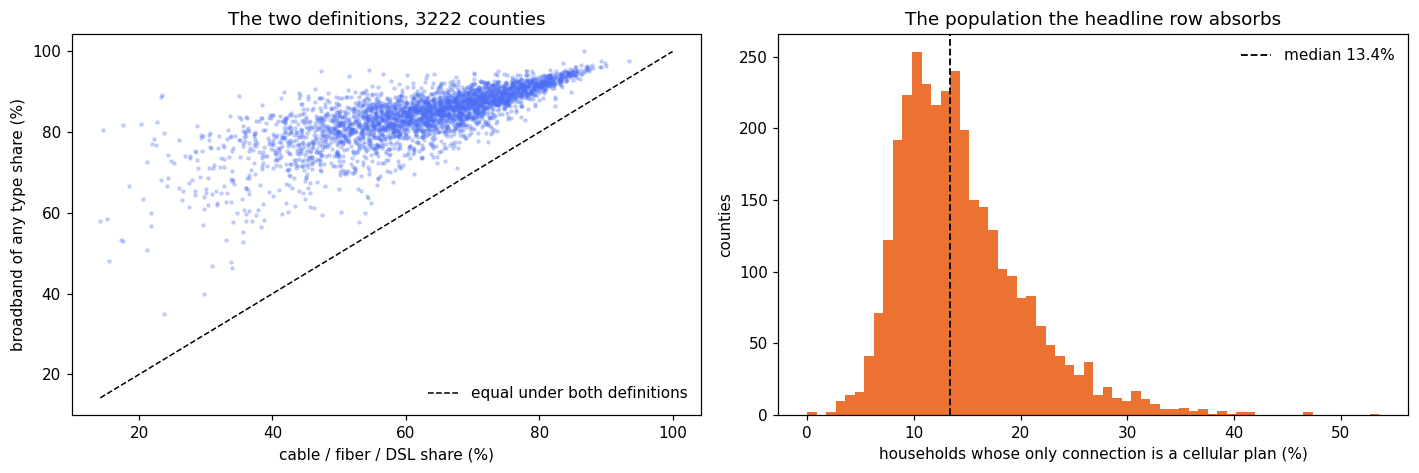

Counties where the two definitions differ by more than 30 pp: 580
Largest definitional gaps:
  Kusilvak Census Area, Alaska                   any-type  80.65%  fixed  14.65%  gap  66.0 pp
  Newton County, Texas                           any-type  89.22%  fixed  23.38%  gap  65.8 pp
  Jasper County, Texas                           any-type  88.69%  fixed  23.26%  gap  65.4 pp
  Culebra Municipio, Puerto Rico                 any-type  81.78%  fixed  17.52%  gap  64.3 pp
  Yakutat City and Borough, Alaska               any-type  82.13%  fixed  20.29%  gap  61.8 pp


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))

axes[0].scatter(fx.share * 100, bb.share * 100, s=4, alpha=0.25, color="#4c6ef5")
_lim = [min(fx.share.min(), bb.share.min()) * 100, 100]
axes[0].plot(_lim, _lim, "k--", lw=1, label="equal under both definitions")
axes[0].set_xlabel("cable / fiber / DSL share (%)")
axes[0].set_ylabel("broadband of any type share (%)")
axes[0].set_title(f"The two definitions, {len(counties)} counties")
axes[0].legend(frameon=False, loc="lower right")

axes[1].hist(co.share * 100, bins=60, color="#e8590c", alpha=0.85)
axes[1].axvline(co.share.median() * 100, color="k", ls="--", lw=1.2,
                label=f"median {co.share.median():.1%}")
axes[1].set_xlabel("households whose only connection is a cellular plan (%)")
axes[1].set_ylabel("counties")
axes[1].set_title("The population the headline row absorbs")
axes[1].legend(frameon=False)
plt.tight_layout(); plt.show()

_vertical = bb.share - fx.share
print(f"Counties where the two definitions differ by more than 30 pp: "
      f"{int((_vertical > 0.30).sum())}")
print("Largest definitional gaps:")
for _i in _vertical.sort_values(ascending=False).head(5).index:
    print(f"  {bb.loc[_i, 'name'][:46]:<46} any-type {bb.loc[_i, 'share']:7.2%}  "
          f"fixed {fx.loc[_i, 'share']:7.2%}  gap {_vertical[_i] * 100:5.1f} pp")

## What county grain costs

The same quantity is published at state level. Comparing the two directly is the cleanest way to
see what the finer geography buys and what it costs, because nothing else changes — same table,
same vintage, same formula.

In [6]:
state_bb = share_estimates(states, DEFINITIONS["broadband_any"][0])
state_moe = np.array([e.moe for e in state_bb])
county_moe = bb.moe.to_numpy()

print("Margin of error on the broadband-of-any-type share")
print(f"  states   (n={len(states):>5}) : median {np.median(state_moe) * 100:6.3f} pp, "
      f"max {state_moe.max() * 100:6.3f} pp")
print(f"  counties (n={len(counties):>5}) : median {np.median(county_moe) * 100:6.3f} pp, "
      f"max {county_moe.max() * 100:6.3f} pp")
print(f"  ratio of medians          : {np.median(county_moe) / np.median(state_moe):.1f}x wider")
print()

households = col(counties, TOTAL)
quintile = pd.qcut(households, 5, labels=["smallest", "2nd", "3rd", "4th", "largest"])
by_size = pd.DataFrame({
    "median_households": pd.Series(households).groupby(quintile, observed=True).median(),
    "median_moe_pp": pd.Series(county_moe * 100).groupby(quintile, observed=True).median(),
})
print("Margin of error by county size")
print(by_size.to_string(float_format="{:,.2f}".format))
print()
print(f"Widest county margins ({DEFINITIONS['broadband_any'][1]}):")
for _i in bb.moe.sort_values(ascending=False).head(5).index:
    print(f"  {bb.loc[_i, 'name'][:44]:<44} households {households[_i]:>8,.0f}  "
          f"share {bb.loc[_i, 'share']:7.2%} +/- {bb.loc[_i, 'moe']:6.2%}")

Margin of error on the broadband-of-any-type share
  states   (n=   52) : median  0.270 pp, max  0.522 pp
  counties (n= 3222) : median  2.337 pp, max 97.304 pp
  ratio of medians          : 8.7x wider

Margin of error by county size
          median_households  median_moe_pp
smallest           1,891.00           4.48
2nd                5,200.00           3.26
3rd               10,218.00           2.52
4th               20,667.00           1.66
largest           83,777.00           0.80

Widest county margins (Broadband of any type (includes cellular)):
  Kalawao County, Hawaii                       households       22  share  95.45% +/- 97.30%
  Kenedy County, Texas                         households       17  share  52.94% +/- 30.03%
  Loving County, Texas                         households       36  share  86.11% +/- 28.52%
  Jeff Davis County, Texas                     households      847  share  80.99% +/- 27.36%
  Covington County, Mississippi                households    7,079  

### A margin of exactly zero is not certainty

The Census proportion formula is

$$\text{MOE}(p) = \frac{1}{Y}\sqrt{\text{MOE}(X)^2 - p^2\,\text{MOE}(Y)^2}.$$

At $p = 1$ the numerator and the denominator are the same count, so $\text{MOE}(X) =
\text{MOE}(Y)$ and the radicand is exactly zero. The formula returns a margin of zero for an
estimate that may rest on a handful of sampled households.

Left unguarded this puts the affected unit at the top of any ranking with apparently no
uncertainty at all. The condition is detectable, and it is detected here.

In [7]:
num_bb = [Estimate(v, m) for v, m in
          zip(col(counties, "B28002_004E"), col(counties, "B28002_004M"))]
den_bb = [Estimate(v, m) for v, m in
          zip(col(counties, TOTAL), col(counties, TOTAL[:-1] + "M"))]
degenerate = np.array([proportion_moe_is_degenerate(n, d)
                       for n, d in zip(num_bb, den_bb)])

print(f"Counties where the proportion formula collapses to a zero margin: "
      f"{int(degenerate.sum())}")
for _i in np.flatnonzero(degenerate):
    print(f"  {bb.loc[_i, 'name'][:44]:<44} households {households[_i]:>7,.0f} "
          f"+/- {col(counties, TOTAL[:-1] + 'M')[_i]:,.0f}")
    print(f"    share {bb.loc[_i, 'share']:.4%}, reported margin "
          f"{bb.loc[_i, 'moe']:.4%}, underlying count margin "
          f"{col(counties, 'B28002_004M')[_i]:,.0f}")
    print(f"    rank by point estimate among {len(counties)} counties: "
          f"{int(bb.share.rank(ascending=False, method='first')[_i])}")
print()
print("The underlying count carries a margin; the proportion does not, because the")
print("two margins cancel at the boundary. Treating the zero as precision would place")
print("a sample of this size first in a national table with no interval at all.")

Counties where the proportion formula collapses to a zero margin: 1
  King County, Texas                           households      90 +/- 35
    share 100.0000%, reported margin 0.0000%, underlying count margin 35


    rank by point estimate among 3222 counties: 1

The underlying count carries a margin; the proportion does not, because the
two margins cancel at the boundary. Treating the zero as precision would place
a sample of this size first in a national table with no interval at all.


## The reliability screen, and what it certifies

The conventional screen computes a coefficient of variation — standard error over estimate — and
suppresses or flags above a cut point. The thresholds used here are the widely applied NCHS ones
and are carried on an object so they print with the result, because they are a convention rather
than a property of the data.

The screen is applied below. Then the ranks are bounded, and the two results are compared.

In [8]:
bb = bb.assign(
    cv=[coefficient_of_variation(e) for e in bb["_est"]],
    reliability=[classify_reliability(e).value for e in bb["_est"]],
)
counts = bb.reliability.value_counts()
print(f"CV screen on the broadband-of-any-type share, {len(bb)} counties")
for cls in (ReliabilityClass.RELIABLE, ReliabilityClass.USE_WITH_CAUTION,
            ReliabilityClass.UNRELIABLE):
    print(f"  {cls.value:<18} {int(counts.get(cls.value, 0)):>5}")
print(f"  median CV          {bb.cv.median():.3%}")
print()

intervals = rank_intervals(
    {f"{i}": e for i, e in enumerate(bb["_est"])}, descending=True
)
bb = bb.assign(
    rank_point=[r.point for r in intervals],
    rank_best=[r.best for r in intervals],
    rank_worst=[r.worst for r in intervals],
    rank_width=[r.width for r in intervals],
)
n = len(bb)
print(f"Rank intervals over the same {n} counties")
print(f"  median interval width : {int(bb.rank_width.median()):,} ranks of {n:,}")
print(f"  mean interval width   : {bb.rank_width.mean():,.0f}")
print(f"  counties with a determined rank (width 1) : {int((bb.rank_width == 1).sum())}")
print(f"  counties whose interval spans over half the field : "
      f"{int((bb.rank_width > n / 2).sum())}")

CV screen on the broadband-of-any-type share, 3222 counties
  reliable            3217
  use_with_caution       3
  unreliable             2
  median CV          1.698%

Rank intervals over the same 3222 counties
  median interval width : 1,481 ranks of 3,222
  mean interval width   : 1,391
  counties with a determined rank (width 1) : 0
  counties whose interval spans over half the field : 1287


In [9]:
reliable = bb.reliability == ReliabilityClass.RELIABLE.value
print("The two screens do not answer the same question")
print(f"  counties passing the CV screen                     : {int(reliable.sum()):,}")
print(f"    ...of those, rank interval wider than 500        : "
      f"{int((reliable & (bb.rank_width > 500)).sum()):,}")
print(f"    ...of those, rank interval wider than 1,000      : "
      f"{int((reliable & (bb.rank_width > 1000)).sum()):,}")
print(f"    ...of those, rank actually determined            : "
      f"{int((reliable & (bb.rank_width == 1)).sum()):,}")
print()
print(f"  correlation, CV with rank-interval width           : "
      f"{np.corrcoef(bb.cv, bb.rank_width)[0, 1]:+.4f}")
print(f"  correlation, margin of error with interval width   : "
      f"{np.corrcoef(bb.moe, bb.rank_width)[0, 1]:+.4f}")
print()
print("A CV screen certifies that the level is precise relative to itself. A share")
print("near 1 divides a modest margin by a large estimate, so the ratio is small")
print("whatever the margin does to the ordering. Screening on the level and then")
print("publishing the rank passes the audit and fails the reader.")

The two screens do not answer the same question
  counties passing the CV screen                     : 3,217
    ...of those, rank interval wider than 500        : 2,907
    ...of those, rank interval wider than 1,000      : 2,379
    ...of those, rank actually determined            : 0

  correlation, CV with rank-interval width           : +0.2701
  correlation, margin of error with interval width   : +0.3433

A CV screen certifies that the level is precise relative to itself. A share
near 1 divides a modest margin by a large estimate, so the ratio is small
whatever the margin does to the ordering. Screening on the level and then
publishing the rank passes the audit and fails the reader.


### Reading a league table against its own bounds

The table below is the one a reader would be shown: the ten highest-connectivity counties in the
country by point estimate. Beside each is the range of ranks that county's confidence interval
actually permits.

In [10]:
top = bb.nsmallest(10, "rank_point")
print(f"Top 10 counties by {DEFINITIONS['broadband_any'][1]}, with attainable rank range")
print(f"{'rank':>4}  {'county':<44} {'share':>9} {'moe':>8}   {'possible ranks':>16}")
for _, r in top.iterrows():
    print(f"{r.rank_point:>4}  {r['name'][:44]:<44} {r.share:>8.3%} "
          f"{r.moe:>8.3%}   {r.rank_best:>6}-{r.rank_worst:<9}")
print()
could_be_first = int((bb.rank_best == 1).sum())
print(f"Counties whose interval permits rank 1 : {could_be_first} of {n:,}")
print(f"Counties in this top 10 whose interval permits a rank outside the top 50 : "
      f"{int((top.rank_worst > 50).sum())} of 10")
print(f"Widest interval in this top 10 : {int(top.rank_width.max()):,} ranks "
      f"({top.loc[top.rank_width.idxmax(), 'name']})")
print()
_pairs = sum(
    difference_is_significant(top['_est'].iloc[i], top['_est'].iloc[j])[0]
    for i in range(len(top)) for j in range(i + 1, len(top))
)
print(f"Within this top 10, distinguishable pairs at 90 percent: "
      f"{_pairs} of {len(top) * (len(top) - 1) // 2}")

Top 10 counties by Broadband of any type (includes cellular), with attainable rank range
rank  county                                           share      moe     possible ranks
   1  King County, Texas                           100.000%   0.000%        1-9        
   2  Falls Church city, Virginia                   97.671%   1.285%        2-54       
   3  Douglas County, Colorado                      97.663%   0.246%        2-31       
   4  Forsyth County, Georgia                       97.242%   0.370%        2-42       
   5  Summit County, Colorado                       97.101%   2.030%        2-121      
   6  Loudoun County, Virginia                      96.654%   0.400%        3-56       
   7  Rockwall County, Texas                        96.616%   0.248%        4-55       
   8  Stafford County, Virginia                     96.404%   0.751%        3-86       
   9  Fairfax city, Virginia                        96.320%   1.919%        2-178      
  10  Fairfax County, Virginia

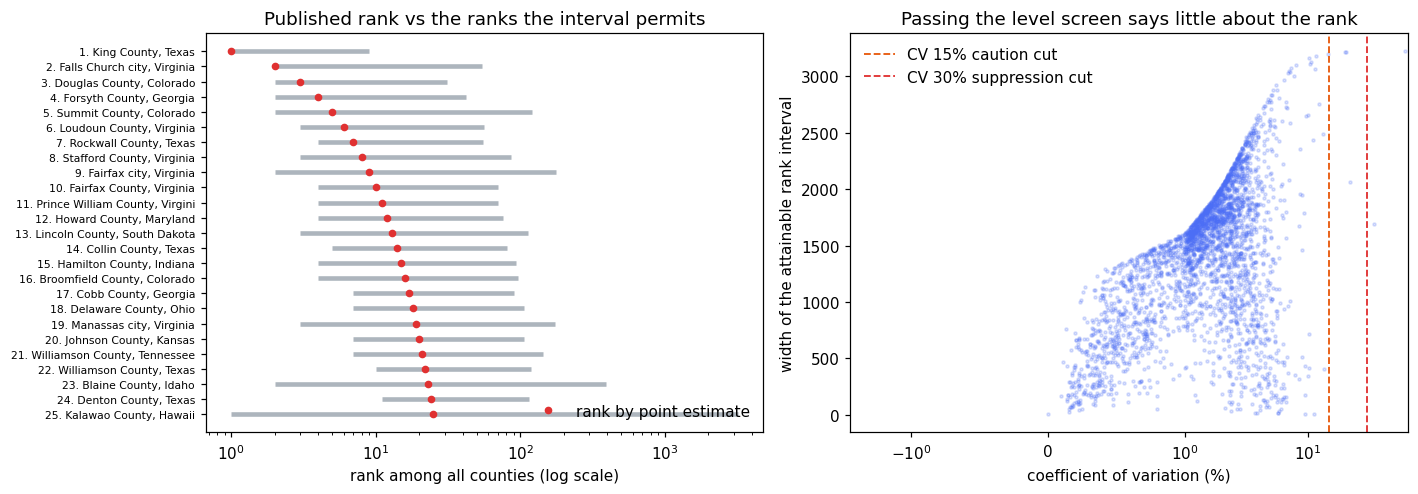

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))

_show = bb.nsmallest(25, "rank_point").sort_values("rank_point")
_y = np.arange(len(_show))
axes[0].hlines(_y, _show.rank_best, _show.rank_worst, color="#adb5bd", lw=3)
axes[0].plot(_show.rank_point, _y, "o", color="#e03131", ms=4, label="rank by point estimate")
axes[0].set_yticks(_y); axes[0].set_yticklabels(
    [f"{r.rank_point}. {r['name'][:30]}" for _, r in _show.iterrows()], fontsize=7)
axes[0].invert_yaxis(); axes[0].set_xscale("log")
axes[0].set_xlabel("rank among all counties (log scale)")
axes[0].set_title("Published rank vs the ranks the interval permits")
axes[0].legend(frameon=False, loc="lower right")

axes[1].scatter(bb.cv * 100, bb.rank_width, s=4, alpha=0.2, color="#4c6ef5")
axes[1].axvline(NCHS_THRESHOLDS.caution * 100, color="#e8590c", ls="--", lw=1.2,
                label=f"CV {NCHS_THRESHOLDS.caution:.0%} caution cut")
axes[1].axvline(NCHS_THRESHOLDS.suppress * 100, color="#e03131", ls="--", lw=1.2,
                label=f"CV {NCHS_THRESHOLDS.suppress:.0%} suppression cut")
axes[1].set_xlabel("coefficient of variation (%)")
axes[1].set_ylabel("width of the attainable rank interval")
axes[1].set_title("Passing the level screen says little about the rank")
axes[1].set_xscale("symlog", linthresh=1)
axes[1].legend(frameon=False)
plt.tight_layout(); plt.show()

## Limitations

- **ACS 5-year estimates are period estimates** spanning 2019–2023. Broadband subscription changed
  materially over that window, including through pandemic-era subsidy programmes that began and
  ended inside it. A 5-year estimate averages over that and describes no single year.
- **Subscription is not availability, and neither is speed.** B28002 records what a household
  reports paying for. A household with no service in an area with fibre at the kerb is recorded
  identically to one with no infrastructure at all. Nothing here measures what is offered, at what
  price, or at what speed; the FCC Broadband Data Collection is the source for availability, and it
  is a different instrument with its own well-documented accuracy disputes.
- **The rank bounds are conservative by construction.** They assume only that each unit's true
  value lies in its published interval. They make no distributional or independence assumption, so
  they cannot understate the ambiguity — and a narrower simulated interval would rest on
  assumptions a published table does not licence.
- **The CV thresholds are a convention.** The 15 and 30 per cent cut points come from NCHS
  guidance; other agencies use other cuts, and no threshold is a property of the data. They are
  printed with the result for that reason.
- **Counties are not a constant unit.** Louisiana parishes, Alaska census areas and independent
  cities are all in this file, with populations spanning four orders of magnitude. A single
  national county ranking treats them as comparable units, which is itself a modelling choice this
  notebook does not defend.
- **No causal claim is available here.** Nothing in this notebook licenses a statement about why a
  county's share is what it is.

In [12]:
"""Findings. Every number below is rendered from a value computed above."""
print("FINDINGS")
print("=" * 78)
print(f"1. The four subscription-type rows are not a partition: they exceed their parent")
print(f"   total in {n_over:,} of {len(counties):,} counties, by a mean factor of "
      f"{ratios.mean():.2f}x.")
print(f"   The three exclusive rows sum to the universe exactly in {n_exact:,} of "
      f"{len(counties):,}.")
print(f"2. 'Broadband of any type' exceeds cable/fiber/DSL by "
      f"{(bb.share.median() - fx.share.median()) * 100:.1f} pp at the median county,")
print(f"   because it counts cellular-only households (median {co.share.median():.1%}, "
      f"max {co.share.max():.1%}).")
print(f"   The two definitions correlate {np.corrcoef(bb.share, fx.share)[0, 1]:.3f}; "
      f"{int((moved >= 100).sum()):,} counties move 100+ ranks between them.")
print(f"3. County margins are {np.median(county_moe) / np.median(state_moe):.1f}x wider "
      f"than state margins on the identical quantity")
print(f"   (median {np.median(county_moe) * 100:.2f} pp vs "
      f"{np.median(state_moe) * 100:.2f} pp).")
print(f"4. {int(reliable.sum()):,} of {n:,} counties pass the CV screen. Of those, "
      f"{int((reliable & (bb.rank_width > 1000)).sum()):,} have a rank interval")
print(f"   wider than 1,000 places and {int((reliable & (bb.rank_width == 1)).sum()):,} "
      f"have a determined rank. CV correlates "
      f"{np.corrcoef(bb.cv, bb.rank_width)[0, 1]:+.2f} with rank-interval width.")
print(f"5. The median county's rank interval spans "
      f"{int(bb.rank_width.median()):,} of {n:,} ranks; "
      f"{could_be_first} counties could occupy rank 1.")
print(f"   Of the published top 10, {int((top.rank_worst > 50).sum())} have intervals "
      f"reaching past rank 50.")
print(f"6. The proportion formula returns a zero margin for "
      f"{int(degenerate.sum())} county at a share of 1.00, on "
      f"{int(households[np.flatnonzero(degenerate)][0]):,} households." if degenerate.sum() == 1
      else f"6. The proportion formula returns a zero margin for "
           f"{int(degenerate.sum())} counties at a share of 1.00.")
print("=" * 78)

FINDINGS
1. The four subscription-type rows are not a partition: they exceed their parent
   total in 3,222 of 3,222 counties, by a mean factor of 2.74x.
   The three exclusive rows sum to the universe exactly in 3,222 of 3,222.
2. 'Broadband of any type' exceeds cable/fiber/DSL by 21.5 pp at the median county,
   because it counts cellular-only households (median 13.4%, max 53.6%).
   The two definitions correlate 0.765; 2,567 counties move 100+ ranks between them.
3. County margins are 8.7x wider than state margins on the identical quantity
   (median 2.34 pp vs 0.27 pp).
4. 3,217 of 3,222 counties pass the CV screen. Of those, 2,379 have a rank interval
   wider than 1,000 places and 0 have a determined rank. CV correlates +0.27 with rank-interval width.
5. The median county's rank interval spans 1,481 of 3,222 ranks; 9 counties could occupy rank 1.
   Of the published top 10, 7 have intervals reaching past rank 50.
6. The proportion formula returns a zero margin for 1 county at a s

## Key Takeaways

1. Indentation in a published table is a hierarchy. Whether the children partition the parent is a
   question about the **labels**, and it is cheap to test: sum them and compare. Here the obvious
   sum overstates its parent in every county in the country, by a factor ranging from about 1.7
   to about 3.1.
2. "Broadband" is not one thing in this table. The row that includes cellular and the row that
   describes a fixed connection rank the country differently, and which one is the right measure
   depends on the question — which is exactly why the choice has to be stated rather than defaulted.
3. Moving from state to county multiplies the margin of error roughly ninefold on the identical
   quantity. Finer geography is not free resolution; it is a trade of precision for granularity,
   and the exchange rate is computable before the analysis rather than after.
4. A coefficient-of-variation screen certifies the **level**. A league table consumes the **rank**.
   For shares near 1 these come apart almost completely: an estimate can be comfortably reliable by
   the conventional screen while its position is undetermined across most of the field.
5. Bound the ranks. The interval-overlap bound is exact, assumption-free, and turns "12th in the
   nation" into "somewhere between 3rd and 47th", which is both less satisfying and true.
6. A margin of exactly zero at a proportion of 1 is an artefact of the formula cancelling at the
   boundary, not a measurement. Detect it explicitly, because unguarded it sorts to the top.

## Exercises

1. **Pick the other definition and redo the argument.** Re-run the ranking, the CV screen and the
   rank bounds on `B28002_007E` (fixed broadband). The shares are further from 1 — does the CV
   screen become more informative about rank stability, and by how much?
2. **Find the counties the definition rescues.** Identify counties in the top decile under
   "broadband of any type" and the bottom half under fixed broadband. What do they have in common,
   and what would a programme targeted off the first list miss?
3. **State-level rank bounds.** Repeat the rank-interval computation on the 52 state-level
   estimates. How much of the improvement comes from wider gaps between units rather than narrower
   margins? Decompose it.
4. **Build a defensible screen.** Design a reliability rule that gates the statistic actually being
   published — rank stability — rather than the level. State what it suppresses and what it costs,
   and apply it to the top-10 table above.
5. **The tolerance question.** `check_partition` defaults to zero tolerance. Find a published ACS
   table where rounding or disclosure control makes exact summation fail, and decide what tolerance
   is defensible there and why it is not simply whatever makes the check pass.
6. **Vintage comparison.** Re-run against ACS 2018 5-Year, before the pandemic-era subsidy
   programmes. Does the cellular-only share move, and does it move where you would predict?

## References

- U.S. Census Bureau. *American Community Survey 2023 5-Year Estimates*, table **B28002**,
  Presence and Types of Internet Subscriptions in Household.
  <https://api.census.gov/data/2023/acs/acs5/groups/B28002.json>
- U.S. Census Bureau. *Understanding and Using American Community Survey Data: What All Data Users
  Need to Know* — margins of error, and the proportion and ratio formulas.
- U.S. Census Bureau. *American Community Survey Design and Methodology*, chapter on variance
  estimation and the treatment of small geographies.
- Parker, J. D., Talih, M., Malec, D. J., et al. (2017). *National Center for Health Statistics
  Data Presentation Standards for Proportions*. Vital and Health Statistics 2(175).
- Federal Communications Commission. *Broadband Data Collection* — availability data, for contrast
  with the subscription measure used here.
- Spiegelhalter, D., Sherlaw-Johnson, C., Bardsley, M., et al. (2012). "Statistical Methods for
  Healthcare Regulation: Rating, Screening and Surveillance." *Journal of the Royal Statistical
  Society, Series A* 175(1), 1–47 — on the instability of institutional league tables.

In [13]:
"""Provenance records for both frames, written beside the notebook."""
#: The repository root, found by walking UP from wherever this runs. Provenance
#: used to be written to `Path.cwd() / "provenance"` in some notebooks and to a
#: repo-root-relative path in others, so the two conventions could not both be
#: satisfied by one working directory -- and a run from the wrong one silently
#: wrote sixteen records into a stray folder at the top of the repo.
REPO_ROOT = next(c for c in (Path.cwd().resolve(), *Path.cwd().resolve().parents)
                 if (c / "src" / "krl_tutorials_data").is_dir())
out_dir = REPO_ROOT / "projects" / "06-infrastructure-environment/D16_internet_and_technology_access" / "provenance"
written = [prov_county.write(out_dir / "d16_b28002_county.json"),
           prov_state.write(out_dir / "d16_b28002_state.json")]

print("Provenance written:")
for p in written:
    print(f"  {p.name}")
print()
print(f"County payload digest : {prov_county.content_sha256[:16]}...")
print(f"State payload digest  : {prov_state.content_sha256[:16]}...")
print(f"Data mode             : {prov_county.mode.value.upper()}")
print(f"Counties              : {len(counties):,}")
print(f"Reliability screen    : {NCHS_THRESHOLDS.source}")

Provenance written:
  d16_b28002_county.json
  d16_b28002_state.json

County payload digest : 1879ea27f28aec0f...
State payload digest  : f3b12400bb12edea...
Data mode             : EMPIRICAL
Counties              : 3,222
Reliability screen    : NCHS Data Presentation Standards for Proportions (convention)
